# Lab 7 · Example A — IMDB Sentiment with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Goal.** Read a movie review and classify it as **positive** or **negative** (binary). You will
turn text into integer indices, pad them, learn **word embeddings**, summarise each review with a
**Bidirectional LSTM**, and decide with a **sigmoid** output.

---
Replace every `None  # TODO (Qn)` with the correct value/code. Run top to bottom.
*(Needs internet once to download the IMDB dataset — works on Colab.)*


## Step 0 — Imports *(given)*

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Load and pad the data

IMDB reviews come **already encoded as integer indices**. Keep the top `num_words` words and pad
every review to `maxlen` tokens.

*Hints:* keep the 10000 most frequent words; pad to length 200.


In [2]:
# Q1a) hyperparameters
num_words = 10000    # Q1a: keep the 10000 most frequent words
maxlen    = 200      # Q1a: fix every review to 200 tokens

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=num_words)

# Q1b) pad both sets to a fixed length
X_train = pad_sequences(X_train, maxlen=maxlen)
X_test  = pad_sequences(X_test,  maxlen=maxlen)

# Q1c) hold out 20% of training data for validation
X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42)

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

       0/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/17464789 ━━━━━━━━━━━━━━━━━━━━ 1:27 5us/step

   49152/17464789 ━━━━━━━━━━━━━━━━━━━━ 57s 3us/step 

   81920/17464789 ━━━━━━━━━━━━━━━━━━━━ 1:06 4us/step

  114688/17464789 ━━━━━━━━━━━━━━━━━━━━ 57s 3us/step 

  147456/17464789 ━━━━━━━━━━━━━━━━━━━━ 52s 3us/step

... (51 outputs left out)

16982016/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

17326080/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


X_train: (20000, 200)  X_val: (5000, 200)  X_test: (25000, 200)


#### Quick check *(given)*

In [3]:
assert X_train.shape[1] == 200, "reviews should be padded to length 200"
assert set(np.unique(y_train)) <= {0, 1}, "labels should be binary (0/1)"
print("Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)")

Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)


## Task 2 — Build the model

Stack: **Embedding** (vocabulary `num_words`, 128-dim vectors) → **Bidirectional LSTM(64)**
returning a single summary vector → **Dropout(0.5)** → **Dense(1, sigmoid)**.

*Hints:* `Embedding(input_dim=num_words, output_dim=128)`; a bidirectional LSTM that returns one
vector uses `return_sequences=False`; one output neuron with a sigmoid gives a probability.


In [4]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding: vocabulary size -> 128-dim word vectors
model.add(Embedding(input_dim=num_words, output_dim=128))

# Q2b) Bidirectional LSTM with 64 units, returning ONE summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))

# Q2c) Dropout to reduce overfitting
model.add(Dropout(0.5))

# Q2d) Output: one neuron, sigmoid (positive/negative probability)
model.add(Dense(1, activation='sigmoid'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378,945 (5.26 MB)

 Trainable params: 1,378,945 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2e.** The Embedding layer shows **1,280,000** parameters. Show why with
`num_words × embed_dim`. Why does this one layer hold most of the model's parameters?

> **Your answer (Q2e):** 1,280,000 = **10,000 × 128** (one 128-dim learned vector for each of the 10,000 words in the vocabulary). It dominates because it stores a full vector for *every* word, whereas the Bidirectional LSTM only needs 2 × 4 × (128 + 64 + 1) × 64 = 98,816 weights (shared across all time steps) and the Dense layer only (128 + 1) × 1 = 129.


## Task 3 — Compile and train

Use the **adam** optimiser, **binary crossentropy** loss (one sigmoid output), track accuracy.
Train 5 epochs, batch size 64, validating on `(X_val, y_val)`.


In [5]:
# Q3a) compile for binary classification
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Q3b) train
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=5,
                    batch_size=64)

Epoch 1/5


  1/313 ━━━━━━━━━━━━━━━━━━━━ 5:31 1s/step - accuracy: 0.3906 - loss: 0.6951

  3/313 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.4427 - loss: 0.6940

  5/313 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.5063 - loss: 0.6926

  7/313 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.4911 - loss: 0.6931

  9/313 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.5122 - loss: 0.6926

... (792 outputs left out)

308/313 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9637 - loss: 0.1020

310/313 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9638 - loss: 0.1016

312/313 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9634 - loss: 0.1019

313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - accuracy: 0.9634 - loss: 0.1020 - val_accuracy: 0.8588 - val_loss: 0.4582


## Task 4 — Evaluate and plot *(fill the blanks)*

  1/782 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9062 - loss: 0.2534

  7/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8929 - loss: 0.3608  

 13/782 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8654 - loss: 0.4620

 19/782 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8602 - loss: 0.4773

 25/782 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8637 - loss: 0.4821

 31/782 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8558 - loss: 0.4912

... (124 outputs left out)

771/782 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8526 - loss: 0.4660

777/782 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8528 - loss: 0.4657

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8532 - loss: 0.4643


Test accuracy: 85.32%


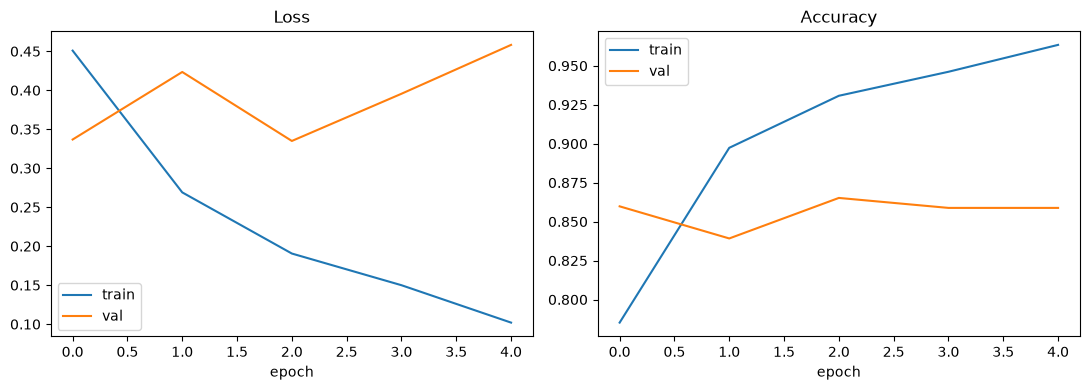

In [6]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 86-88%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

## Task 5 — Predict on your own text *(fill the blanks)*

IMDB reserves indices 0–2 (pad / start / unknown), so real words are **offset by 3**.


In [7]:
word_index = imdb.get_word_index()

def predict_sentiment(review):
    enc = [word_index.get(w, 0) + 3 for w in review.lower().split()]
    padded = pad_sequences([enc], maxlen=maxlen)
    p = model.predict(padded, verbose=0)[0][0]
    # Q5) threshold the sigmoid at 0.5
    return "Positive" if p >= 0.5 else "Negative"

for r in ["this film was absolutely wonderful and moving",
          "a boring dull waste of time"]:
    print(f"{predict_sentiment(r):8s} <- {r}")

      0/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  16384/1641221 ━━━━━━━━━━━━━━━━━━━━ 7s 5us/step

  32768/1641221 ━━━━━━━━━━━━━━━━━━━━ 7s 5us/step

  49152/1641221 ━━━━━━━━━━━━━━━━━━━━ 8s 6us/step

  81920/1641221 ━━━━━━━━━━━━━━━━━━━━ 9s 6us/step

 114688/1641221 ━━━━━━━━━━━━━━━━━━━━ 7s 5us/step

... (11 outputs left out)

 983040/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

1327104/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step


Positive <- this film was absolutely wonderful and moving
Negative <- a boring dull waste of time


## Task 6 — Short questions *(write answers here)*

1. Why do we **pad** every review to the same length?
2. What does the **Embedding** layer do that one-hot encoding of words would not?
3. Why `return_sequences=False` here (unlike the music lab)?
4. Why `sigmoid` + `binary_crossentropy` instead of `softmax` + `categorical_crossentropy`?
5. In your accuracy plot, does validation loss start rising? What does that indicate, and what
   does `Dropout(0.5)` do about it?

> **Your answers:**
>
> 1. Reviews have different lengths, but a batch must be a rectangular tensor of shape `(batch, maxlen)`. Padding (with the reserved index 0) or truncating every review to 200 tokens gives a fixed shape so the network can be trained efficiently in batches.
>
> 2. The Embedding layer maps each word index to a small, dense, **trainable** 128-dim vector. Similar words ("great", "excellent") end up close together, so meaning is captured. One-hot vectors are huge (10,000-long, mostly zeros) and treat every pair of words as equally different.
>
> 3. We need only **one** label per review, so we only need one summary vector of the whole sequence (the final states of the forward and backward LSTMs). In the music lab a prediction was needed at every time step, so the full sequence of outputs was returned (`return_sequences=True`).
>
> 4. The task is **binary**: one sigmoid neuron outputs P(positive) directly, and binary cross-entropy is the matching loss for a single 0/1 label. Softmax + categorical cross-entropy would need 2 output neurons and one-hot labels to do the same job, which is redundant.
>
> 5. Yes, validation loss usually stops falling after about 2 epochs and then rises while training loss keeps dropping. This means **overfitting**: the model is memorising the training reviews. `Dropout(0.5)` randomly switches off half of the LSTM outputs during training, so the Dense layer cannot depend on a few specific features. This regularises the model and reduces (but does not fully remove) overfitting. Early stopping would also help.
